In [3]:
import json
import random
import cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tensorflow.keras import layers
import tensorflow as tf
from pycocotools.coco import COCO
import os
import glob
import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from sklearn.model_selection import train_test_split

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
!pip install pycocotools

In [4]:
IMAGE_DIR = "/content/drive/MyDrive/Kidney_data/image"
LABEL_DIR = "/content/drive/MyDrive/Kidney_data/label"

IMG_HEIGHT = 128
IMG_WIDTH = 128
BATCH_SIZE = 8

In [5]:
image_files = sorted(
    glob.glob(os.path.join(IMAGE_DIR, "*.tif"))
)

label_files = sorted(
    glob.glob(os.path.join(LABEL_DIR, "*.tif"))
)

print("Number of images:", len(image_files))
print("Number of labels:", len(label_files))

print("\nFirst image:", image_files[0])
print("First label:", label_files[0])

Number of images: 838
Number of labels: 838

First image: /content/drive/MyDrive/Kidney_data/image/1.tif
First label: /content/drive/MyDrive/Kidney_data/label/1.tif


In [6]:
image = cv2.imread(
    image_files[0],
    cv2.IMREAD_GRAYSCALE
)

label = cv2.imread(
    label_files[0],
    cv2.IMREAD_GRAYSCALE
)

print("Image shape:", image.shape)
print("Label shape:", label.shape)

print("Image values:",
      np.unique(image)[:20])

print("Label values:",
      np.unique(label))

Image shape: (512, 512)
Label shape: (512, 512)
Image values: [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19]
Label values: [  0   1   2   3   4   5 251 252 253 254 255]


In [7]:
def load_image_and_label(image_path, label_path):

    # Read image
    image = cv2.imread(
        image_path,
        cv2.IMREAD_GRAYSCALE
    )

    # Read label
    label = cv2.imread(
        label_path,
        cv2.IMREAD_GRAYSCALE
    )

    # Resize image
    image = cv2.resize(
        image,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_AREA
    )

    # Resize label
    # IMPORTANT: use NEAREST for masks
    label = cv2.resize(
        label,
        (IMG_WIDTH, IMG_HEIGHT),
        interpolation=cv2.INTER_NEAREST
    )

    # Normalize image
    image = image.astype(np.float32) / 255.0

    # Add channel dimension
    image = np.expand_dims(image, axis=-1)

    # Label should NOT be normalized like an image
    label = label.astype(np.uint8)

    return image, label

In [8]:
X = []
Y = []

for image_path, label_path in zip(
        image_files,
        label_files):

    image, label = load_image_and_label(
        image_path,
        label_path
    )

    X.append(image)
    Y.append(label)

X = np.array(X)
Y = np.array(Y)

print("X shape:", X.shape)
print("Y shape:", Y.shape)

X shape: (838, 128, 128, 1)
Y shape: (838, 128, 128)


In [9]:
print("Unique label values:")
print(np.unique(Y))

Unique label values:
[  0   1   2   3   4   5   6   7 247 248 249 250 251 252 253 254 255]


In [10]:
#Y = (Y == 255).astype(np.float32)

print(np.unique(Y))

[  0   1   2   3   4   5   6   7 247 248 249 250 251 252 253 254 255]


In [11]:
print("X shape:", X.shape)
print("Y shape:", Y.shape)
print("Number of images:", len(X))
print("Number of masks:", len(Y))

X shape: (838, 128, 128, 1)
Y shape: (838, 128, 128)
Number of images: 838
Number of masks: 838


In [12]:
X.shape  # (N, 128, 128, 1)

(838, 128, 128, 1)

In [13]:
Y.shape  # (N, 128, 128)

(838, 128, 128)

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,      # 20% testing, 80% training
    random_state=42,
    shuffle=True
)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)

print("X_test:", X_test.shape)
print("Y_test:", Y_test.shape)

X_train: (670, 128, 128, 1)
Y_train: (670, 128, 128)
X_test: (168, 128, 128, 1)
Y_test: (168, 128, 128)


In [16]:
import numpy as np
import matplotlib.pyplot as plt

def show_random_images_masks(X, Y, n=5):

    # Random sample indices
    indices = np.random.choice(
        len(X),
        size=min(n, len(X)),
        replace=False
    )

    plt.figure(figsize=(15, 4 * len(indices)))

    for row, idx in enumerate(indices):

        # Remove channel dimension
        image = X[idx].squeeze()
        mask = Y[idx].squeeze()

        # -------------------------
        # 1. Original Image
        # -------------------------
        plt.subplot(len(indices), 3, 3 * row + 1)

        plt.imshow(image, cmap="gray")
        plt.title(f"Image {idx}")
        plt.axis("off")

        # -------------------------
        # 2. Mask
        # -------------------------
        plt.subplot(len(indices), 3, 3 * row + 2)

        plt.imshow(mask, cmap="gray")
        plt.title(f"Mask {idx}")
        plt.axis("off")

        # -------------------------
        # 3. Image + Mask
        # -------------------------
        plt.subplot(len(indices), 3, 3 * row + 3)

        plt.imshow(image, cmap="gray")
        plt.imshow(
            mask,
            alpha=0.4,
            cmap="jet"
        )

        plt.title(f"Image + Mask {idx}")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [17]:
import gc #Clearing Memory
import torch

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

In [ ]:
#show_random_images_masks(X, Y, n=5)

In [ ]:
'''def show_random_bbox(images_dir, masks_dir, n=5):

    # -----------------------------------------
    # Get image and mask filenames
    # -----------------------------------------
    image_files = sorted([
        f for f in os.listdir(images_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.tif', '.tiff'))
    ])

    mask_files = sorted([
        f for f in os.listdir(masks_dir)
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.tif', '.tiff'))
    ])

    # -----------------------------------------
    # Find common filenames
    # -----------------------------------------
    image_names = {os.path.splitext(f)[0]: f for f in image_files}
    mask_names = {os.path.splitext(f)[0]: f for f in mask_files}

    common_names = sorted(
        set(image_names.keys()) & set(mask_names.keys())
    )

    if len(common_names) == 0:
        raise ValueError(
            "No matching image and mask filenames found."
        )

    # -----------------------------------------
    # Random samples
    # -----------------------------------------
    samples = random.sample(
        common_names,
        min(n, len(common_names))
    )

    # -----------------------------------------
    # Display
    # -----------------------------------------
    for name in samples:

        image_path = os.path.join(
            images_dir,
            image_names[name]
        )

        mask_path = os.path.join(
            masks_dir,
            mask_names[name]
        )

        # Load image and mask
        image = np.array(Image.open(image_path))
        mask = np.array(Image.open(mask_path))

        # -----------------------------------------
        # Convert mask to 2D
        # -----------------------------------------
        if mask.ndim == 3:
            # If mask is RGB/grayscale with channels
            if mask.shape[-1] == 1:
                mask = mask[:, :, 0]
            else:
                # If mask is one-hot encoded
                mask = np.argmax(mask, axis=-1)

        # -----------------------------------------
        # Binary mask
        # 0 = background
        # 1 = object
        # -----------------------------------------
        binary_mask = (mask > 0).astype(np.uint8)

        # -----------------------------------------
        # Convert image to RGB
        # -----------------------------------------
        if image.ndim == 2:
            image_rgb = cv2.cvtColor(
                image,
                cv2.COLOR_GRAY2RGB
            )
        elif image.shape[-1] == 1:
            image_rgb = cv2.cvtColor(
                image[:, :, 0],
                cv2.COLOR_GRAY2RGB
            )
        else:
            image_rgb = image.copy()

        # -----------------------------------------
        # Find bounding box
        # -----------------------------------------
        ys, xs = np.where(binary_mask > 0)

        if len(xs) > 0:

            x_min = xs.min()
            x_max = xs.max()

            y_min = ys.min()
            y_max = ys.max()

            # Draw bounding box
            cv2.rectangle(
                image_rgb,
                (x_min, y_min),
                (x_max, y_max),
                (255, 0, 0),
                3
            )

            # Add label
            cv2.putText(
                image_rgb,
                "Class 1",
                (x_min, max(y_min - 10, 20)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.7,
                (255, 0, 0),
                2
            )

            print(
                f"{name}: "
                f"BBox = ({x_min}, {y_min}, "
                f"{x_max}, {y_max})"
            )

        else:
            print(f"{name}: No object found")

        # -----------------------------------------
        # Plot
        # -----------------------------------------
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(image)
        plt.title("Original Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(mask, cmap="gray")
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(image_rgb)
        plt.title("Image + Bounding Box")
        plt.axis("off")

        plt.tight_layout()
        plt.show()'''

In [18]:
def show_bbox_class255(image_dir, mask_dir, n=5):

    # Get image files
    image_files = sorted([
        f for f in os.listdir(image_dir)
        if f.lower().endswith(
            ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
        )
    ])

    # Get mask files
    mask_files = sorted([
        f for f in os.listdir(mask_dir)
        if f.lower().endswith(
            ('.png', '.jpg', '.jpeg', '.tif', '.tiff')
        )
    ])

    # Make sure numbers match
    print("Number of images:", len(image_files))
    print("Number of masks:", len(mask_files))

    # Select random indices
    indices = random.sample(
        range(min(len(image_files), len(mask_files))),
        min(n, len(image_files), len(mask_files))
    )

    for idx in indices:

        # -----------------------------
        # Load image
        # -----------------------------
        image_path = os.path.join(
            image_dir,
            image_files[idx]
        )

        image = np.array(
            Image.open(image_path)
        )

        # -----------------------------
        # Load mask
        # -----------------------------
        mask_path = os.path.join(
            mask_dir,
            mask_files[idx]
        )

        mask = np.array(
            Image.open(mask_path)
        )

        # Remove channel if necessary
        if mask.ndim == 3:
            mask = mask[:, :, 0]

        # -----------------------------
        # ONLY CLASS 255
        # -----------------------------
        class255 = (mask == 255).astype(np.uint8)

        # -----------------------------
        # Find bounding box
        # -----------------------------
        ys, xs = np.where(class255 > 0)

        # Convert image to RGB
        if image.ndim == 2:
            image_rgb = cv2.cvtColor(
                image,
                cv2.COLOR_GRAY2RGB
            )
        else:
            image_rgb = image.copy()

        # -----------------------------------------
        # Convert image to RGB
        # -----------------------------------------
        if image.ndim == 2:
            image_rgb = cv2.cvtColor(
                image,
                cv2.COLOR_GRAY2RGB
            )
        elif image.shape[-1] == 1:
            image_rgb = cv2.cvtColor(
                image[:, :, 0],
                cv2.COLOR_GRAY2RGB
            )
        else:
            image_rgb = image.copy()


        # Normalize image for display
        if image_rgb.max() <= 1:
            image_rgb = (
                image_rgb * 255
            ).astype(np.uint8)
        else:
            image_rgb = image_rgb.astype(np.uint8)

        # -----------------------------
        # Draw bbox
        # -----------------------------
        if len(xs) > 0:

            x_min = xs.min()
            x_max = xs.max()
            y_min = ys.min()
            y_max = ys.max()

            cv2.rectangle(
                image_rgb,
                (x_min, y_min),
                (x_max, y_max),
                (255, 0, 0),
                2
            )
            cv2.putText(
    image_rgb,
    "Kidney Stones",
    (int(x_min), int(max(y_min - 10, 20))),
    cv2.FONT_HERSHEY_SIMPLEX,
    0.9,              # fontScale
    (255, 0, 0),      # color
    2,                # thickness
    cv2.LINE_AA
)
            print(
                image_files[idx],
                "->",
                f"bbox=({x_min},{y_min},"
                f"{x_max},{y_max})"
            )

        else:
            print(
                image_files[idx],
                "-> Class 255 not found"
            )

        # -----------------------------
        # Display
        # -----------------------------
        plt.figure(figsize=(15, 5))

        plt.subplot(1, 3, 1)
        plt.imshow(image)
        plt.title("Original Image")
        plt.axis("off")


        plt.subplot(1, 3, 2)
        plt.imshow(mask)
        plt.title("Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(image_rgb)
        plt.title("Image + Class 255 Bounding Box")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

Number of images: 838
Number of masks: 838
834.tif -> bbox=(206,214,214,222)


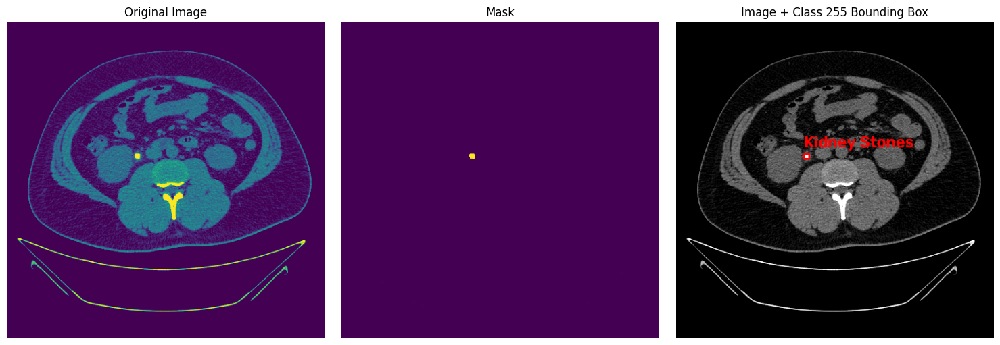

1031.tif -> bbox=(293,280,309,300)


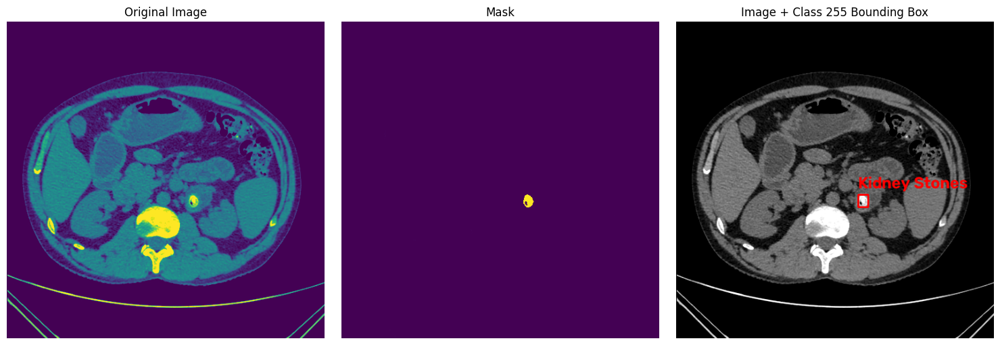

1322.tif -> bbox=(344,222,354,231)


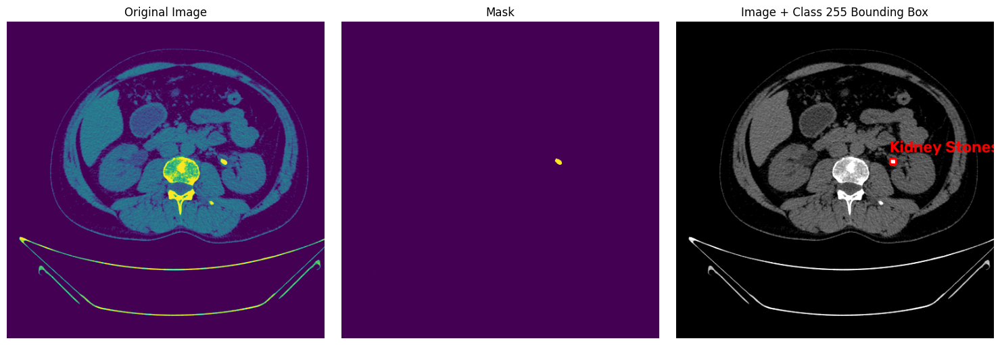

1041.tif -> bbox=(294,270,324,300)


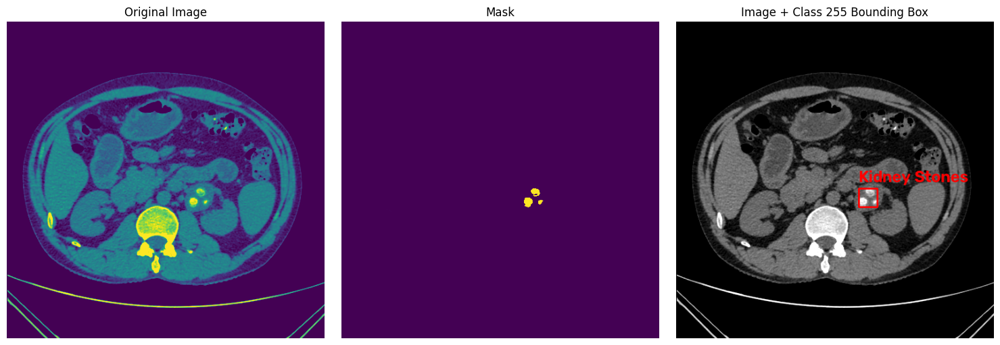

520.tif -> bbox=(192,251,303,288)


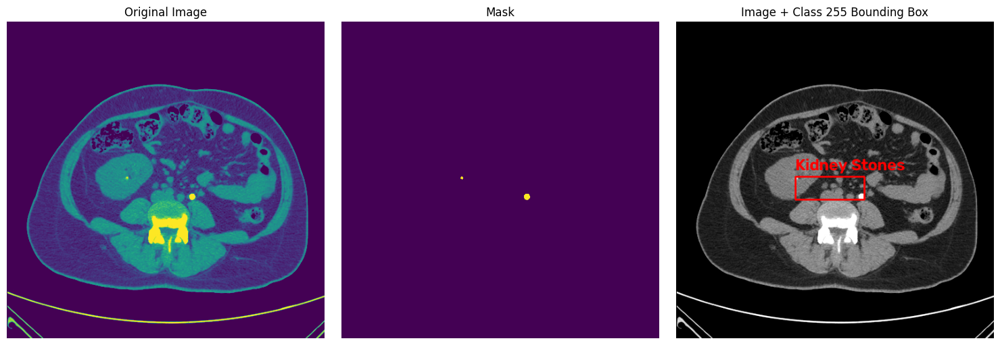

In [19]:
show_bbox_class255(
    IMAGE_DIR,
    LABEL_DIR,
    n=5
)

In [20]:
!pip install -qU ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.1/78.1 kB 5.8 MB/s eta 0:00:00


In [ ]:
'''from ultralytics import SAM
import matplotlib.pyplot as plt

# load the model
model = SAM('sam2.1_b.pt')

# display model info
model.info()'''

Model summary: 436 layers, 80,850,178 parameters, 80,850,178 gradients


(436, 80850178, 80850178, 0.0)

# Segment Image.

# Using SAM (Segment Anything Model).

In [21]:
!pip install git+https://github.com/facebookresearch/segment-anything.git

  Cloning https://github.com/facebookresearch/segment-anything.git to /tmp/pip-req-build-inzoupbz
  Running command git clone --filter=blob:none --quiet https://github.com/facebookresearch/segment-anything.git /tmp/pip-req-build-inzoupbz
  Resolved https://github.com/facebookresearch/segment-anything.git to commit dca509fe793f601edb92606367a655c15ac00fdf
  Preparing metadata (setup.py) ... done
  Created wheel for segment_anything: filename=segment_anything-1.0-py3-none-any.whl size=36634 sha256=ce67bbaba61359ec2449299b18694afca039cabea228ca1bf529ea79a2292449
  Stored in directory: /tmp/pip-ephem-wheel-cache-oqq5liuz/wheels/5d/7b/4a/c7fda89f2e27647dd0816f51ea103992b1b6f0f53ad234895c
Successfully built segment_anything


In [22]:
from segment_anything import (
    sam_model_registry,
    SamPredictor
)

In [23]:
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Using:", device)

sam = sam_model_registry["vit_b"](
    checkpoint="/content/drive/MyDrive/sam_vit_b_01ec64.pth"
)

sam.to(device=device)

predictor = SamPredictor(sam)

Using: cpu


In [24]:
def get_bbox_from_mask(mask):

    # Make sure mask is 2D
    if mask.ndim == 3:
        mask = mask.squeeze()

    # Only class 255
    binary_mask = (mask == 255).astype(np.uint8)
    #binary_mask = (mask == 1).astype(np.uint8)
    ys, xs = np.where(binary_mask > 0)

    if len(xs) == 0:
        return None

    x_min = xs.min()
    y_min = ys.min()
    x_max = xs.max()
    y_max = ys.max()

    return np.array(
        [x_min, y_min, x_max, y_max]
    )

In [25]:
def sam_segment(image, bbox):

    # Convert grayscale image to RGB
    if image.ndim == 2:
        image_rgb = cv2.cvtColor(
            image,
            cv2.COLOR_GRAY2RGB
        )

    elif image.shape[-1] == 1:
        image_rgb = cv2.cvtColor(
            image[:, :, 0],
            cv2.COLOR_GRAY2RGB
        )

    else:
        image_rgb = image.copy()

    # Convert to uint8
    if image_rgb.max() <= 1:
        image_rgb = (
            image_rgb * 255
        ).astype(np.uint8)

    else:
        image_rgb = image_rgb.astype(np.uint8)

    # SAM requires RGB image
    predictor.set_image(image_rgb)

    # Predict mask using bounding box
    masks, scores, logits = predictor.predict(
        box=bbox,
        multimask_output=False
    )

    # Select best mask
    best_index = np.argmax(scores)

    best_mask = masks[best_index]

    return image_rgb, best_mask, scores

In [26]:
def show_sam_segmentation(X, Y, n=5):

    indices = np.random.choice(
        len(X),
        size=min(n, len(X)),
        replace=False
    )

    for idx in indices:

        image = X[idx]
        mask = Y[idx]

        # Remove channel dimension
        if image.ndim == 3 and image.shape[-1] == 1:
            image = image[:, :, 0]

        if mask.ndim == 3 and mask.shape[-1] == 1:
            mask = mask[:, :, 0]

        # Get bbox from class 255
        bbox = get_bbox_from_mask(mask)

        if bbox is None:
            print(
                f"Image {idx}: "
                "Class 255 not found"
            )
            continue

        # SAM segmentation
        image_rgb, sam_mask, scores = sam_segment(
            image,
            bbox
        )

        # -----------------------------
        # Plot
        # -----------------------------
        plt.figure(figsize=(16, 5))
        ax = plt.gca()
        # -----------------------------------------
        # Convert image to RGB
        # -----------------------------------------
        if image.ndim == 2:
            image_rgb = cv2.cvtColor(
                image,
                cv2.COLOR_GRAY2RGB
            )
        elif image.shape[-1] == 1:
            image_rgb = cv2.cvtColor(
                image[:, :, 0],
                cv2.COLOR_GRAY2RGB
            )
        else:
            image_rgb = image.copy()

        # Original image
        plt.subplot(1, 4, 1)
        plt.imshow(image_rgb)
        plt.title("Original Image")
        plt.axis("off")

        # Ground truth
        plt.subplot(1, 4, 2)
        plt.imshow(mask)
        plt.title("Ground Truth")
        plt.axis("off")

        # Bounding box
        plt.subplot(1, 4, 3)
        plt.imshow(image_rgb)

        x1, y1, x2, y2 = bbox

        plt.gca().add_patch(
            plt.Rectangle(
                (x1, y1),
                x2 - x1,
                y2 - y1,
                fill=False,
                color="red",
                linewidth=2
            )

        )
        ax.text(
    x1,
    y1 - 5,
    "Kidney Stone",
    color="red",
    fontsize=10,
    fontweight="bold",
    verticalalignment="bottom"
)

        plt.title("Bounding Box")
        plt.axis("off")

        # SAM result
        plt.subplot(1, 4, 4)
        plt.imshow(image_rgb)
        plt.imshow(
            sam_mask,
            alpha=0.5,
            cmap="jet"
        )

        plt.title(
            f"SAM Mask\nScore={scores[np.argmax(scores)]:.3f}"
        )

        plt.axis("off")

        #plt.tight_layout()
        plt.show()

In [ ]:
show_sam_segmentation(X, Y, n=5)

# Using UNET Model for segmenatation.

In [1]:
def double_conv_block(x, n_filters):
    x = layers.Conv2D(n_filters, 3, padding='same', activation='relu', kernel_initializer='he_normal')(x)
    x = layers.Conv2D(n_filters, 3, padding='same', activation='relu', kernel_initializer='he_normal')(x)
    return x

def downsample_block(x, n_filters):
    f = double_conv_block(x, n_filters)
    p = layers.MaxPool2D(2)(f)
    p = layers.Dropout(0.3)(p)
    return f, p

def upsample_block(x, conv_features, n_filters):
    x = layers.Conv2DTranspose(n_filters, 3, 2, padding='same')(x)
    x = layers.concatenate([x, conv_features])
    x = layers.Dropout(0.3)(x)
    x = double_conv_block(x, n_filters)
    return x

In [2]:
def build_unet_model(output_channels):
    # input layer
    inputs = layers.Input(shape=(128, 128, 1))

    # encoder - downsample
    f1, p1 = downsample_block(inputs, 64)
    f2, p2 = downsample_block(p1, 128)
    f3, p3 = downsample_block(p2, 256)
    f4, p4 = downsample_block(p3, 512)

    # intermediate block
    intermediate_block = double_conv_block(p4, 1024)

    # decoder - upsample
    u6 = upsample_block(intermediate_block, f4, 512)
    u7 = upsample_block(u6, f3, 256)
    u8 = upsample_block(u7, f2, 128)
    u9 = upsample_block(u8, f1, 64)

    # output layer
    outputs = layers.Conv2D(output_channels, 1, padding='same', activation='softmax')(u9)

    # unet model
    unet_model = tf.keras.Model(inputs, outputs, name='U-Net')

    return unet_model

In [3]:
output_channels = 1
model = build_unet_model(output_channels)
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
#model.compile(optimizer='adam',
 #             loss='sparse_categorical_crossentropy', metrics=['accuracy'])

NameError: name 'layers' is not defined

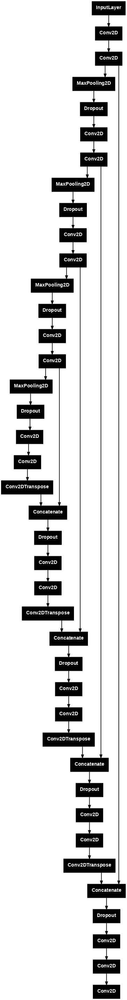

In [ ]:
tf.keras.utils.plot_model(model, show_shapes=False, expand_nested=False, dpi=64)

# Training the UNet Model.

In [ ]:
BATCH_SIZE = 16

Train_dataset = tf.data.Dataset.from_tensor_slices(
    (X_train, Y_train)
)

Train_dataset = (
    Train_dataset
    .shuffle(len(X_train))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [ ]:
Test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, Y_test)
)

Test_dataset = (
    Test_dataset
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [ ]:
Test_dataset = tf.data.Dataset.from_tensor_slices(
    (X_test, Y_test)
)

Test_dataset = Test_dataset.batch(
    BATCH_SIZE
).prefetch(tf.data.AUTOTUNE)

In [ ]:
for images, masks in Train_dataset.take(1):

    print("Images:", images.shape)
    print("Masks:", masks.shape)
    print("Mask values:", np.unique(masks.numpy()))

Images: (16, 128, 128, 1)
Masks: (16, 128, 128)
Mask values: [0. 1.]


In [ ]:
Y_train = np.expand_dims(Y_train, axis=-1)
Y_test = np.expand_dims(Y_test, axis=-1)

print(Y_train.shape)
print(Y_test.shape)

(670, 128, 128, 1)
(168, 128, 128, 1)


In [ ]:
EPOCHS = 1

steps_per_epoch = len(X_train) // BATCH_SIZE
validation_steps = len(X_test) // BATCH_SIZE

history = model.fit(
    Train_dataset,
    epochs=EPOCHS,
    steps_per_epoch=steps_per_epoch,
    validation_data=Test_dataset,
    validation_steps=validation_steps
)


Epoch 1/2


# Visualizing the Results.

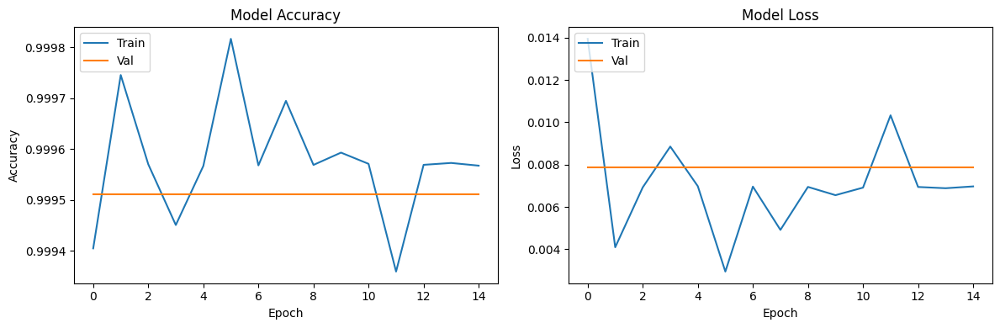

In [ ]:
# plot train & val accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Val'], loc='upper left')

# plot train & val loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend(['Train', 'Val'], loc='upper left')

plt.tight_layout()
plt.show()

# Test Predictions.

In [ ]:
def display_sample(display_list):
    plt.figure(figsize=(20, 10))

    titles = ["Input Image", "True Mask", "Predicted Mask"]

    for i, item in enumerate(display_list):

        # Convert TensorFlow tensor to NumPy
        item = item.numpy() if hasattr(item, "numpy") else item
        item = np.squeeze(item)

        plt.subplot(1, 3, i + 1)

        if i == 0:
            # Input image: (128,128,3)
            plt.imshow(item)
        else:
            # Mask: (128,128)
            plt.imshow(item, cmap="gray")

        plt.title(titles[i])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
def display_sample2(display_list):

    plt.figure(figsize=(24, 7))

    titles = [
        "Input Image",
        "True Mask",
        "Image + Predicted Mask",
        "Predicted Mask + Bounding Box"
    ]

    # Convert input image
    image = display_list[0]
    image = image.numpy() if hasattr(image, "numpy") else image
    image = np.squeeze(image)

    # Convert true mask
    true_mask = display_list[1]
    true_mask = true_mask.numpy() if hasattr(true_mask, "numpy") else true_mask
    true_mask = np.squeeze(true_mask)

    # Convert predicted mask
    pred_mask = display_list[2]
    pred_mask = pred_mask.numpy() if hasattr(pred_mask, "numpy") else pred_mask
    pred_mask = np.squeeze(pred_mask)

    # ------------------------------------------------
    # 1. Input Image
    # ------------------------------------------------
    ax1 = plt.subplot(1, 4, 1)

    ax1.imshow(image, cmap="gray")
    ax1.set_title(titles[0])
    ax1.axis("off")

    # ------------------------------------------------
    # 2. True Mask
    # ------------------------------------------------
    ax2 = plt.subplot(1, 4, 2)

    ax2.imshow(true_mask, cmap="gray")
    ax2.set_title(titles[1])
    ax2.axis("off")

    # ------------------------------------------------
    # 3. Image + Predicted Mask
    # ------------------------------------------------
    ax3 = plt.subplot(1, 4, 3)

    ax3.imshow(image, cmap="gray")
    ax3.imshow(
        pred_mask,
        cmap="jet",
        alpha=0.5,
        interpolation="nearest"
    )

    ax3.set_title(titles[2])
    ax3.axis("off")

    # ------------------------------------------------
    # 4. Predicted Mask + Bounding Box
    # ------------------------------------------------
    ax4 = plt.subplot(1, 4, 4)

    ax4.imshow(image, cmap="gray")

    ax4.imshow(
        pred_mask,
        cmap="jet",
        alpha=0.5,
        interpolation="nearest"
    )

    # Find foreground pixels
    ys, xs = np.where(pred_mask > 0)

    if len(xs) > 0 and len(ys) > 0:

        x_min = xs.min()
        x_max = xs.max()

        y_min = ys.min()
        y_max = ys.max()

        width = x_max - x_min + 1
        height = y_max - y_min + 1

        # Bounding box
        rectangle = patches.Rectangle(
            (x_min, y_min),
            width,
            height,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax4.add_patch(rectangle)

        # Display coordinates
        ax4.text(
            x_min,
            max(0, y_min - 5),
            f"Box: ({x_min}, {y_min}, "
            f"{width}, {height})",
            color="red",
            fontsize=10,
            backgroundcolor="white"
        )

    else:
        ax4.text(
            0.5,
            0.5,
            "No predicted foreground",
            transform=ax4.transAxes,
            ha="center",
            va="center",
            color="red",
            fontsize=12
        )

    ax4.set_title(titles[3])
    ax4.axis("off")

    plt.tight_layout()
    plt.show()

In [ ]:
def create_mask(pred_mask, threshold=0.05):

    # Model output shape:
    # (batch, 128, 128, 1)

    pred_mask = tf.cast(
        pred_mask > threshold,
        tf.uint8
    )

    return pred_mask[0]

In [ ]:
def show_predictions2(dataset=None, num=1):

    if dataset is not None:

        for image, mask in dataset.take(num):

            pred_mask = model.predict(
                image,
                verbose=0
            )

            predicted_mask = create_mask(
                pred_mask,
                threshold=0.1
            )

            display_sample2([
                image[0],
                mask[0],
                predicted_mask
            ])

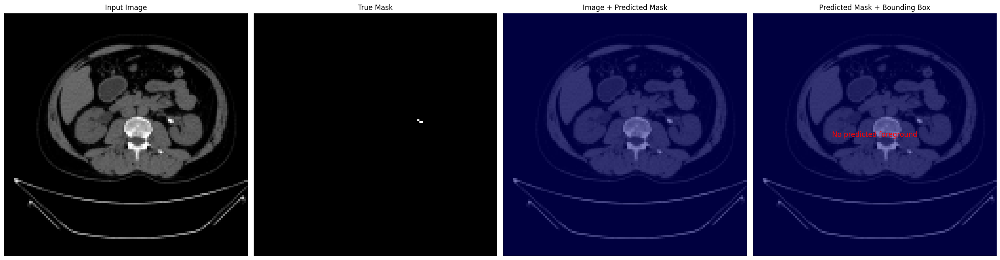

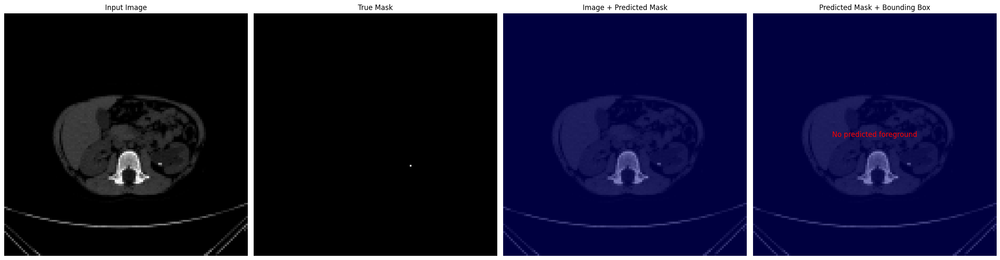

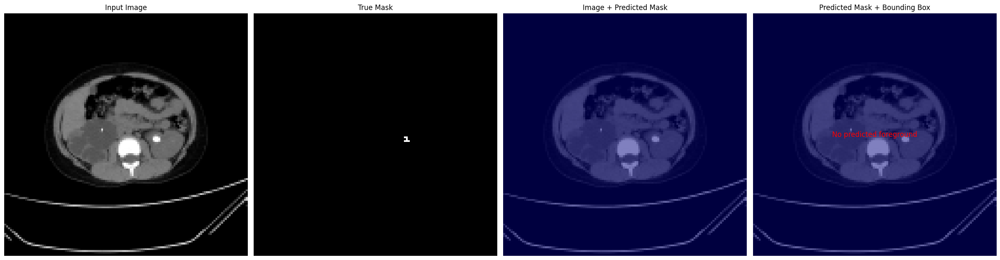

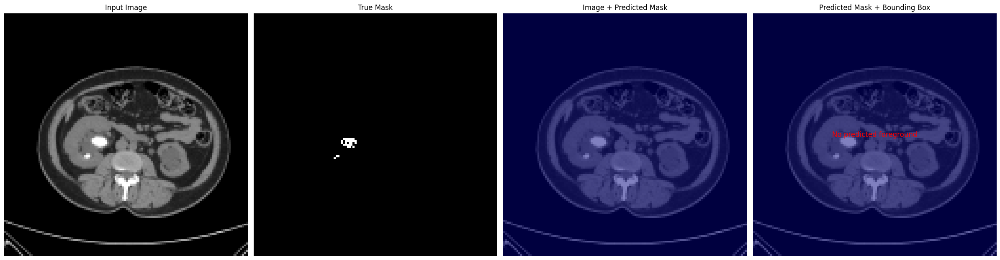

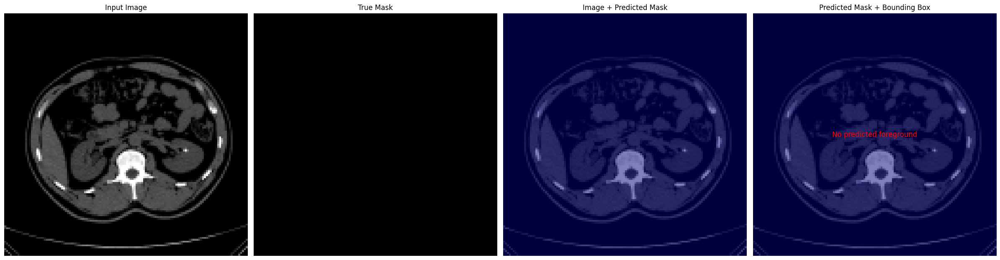

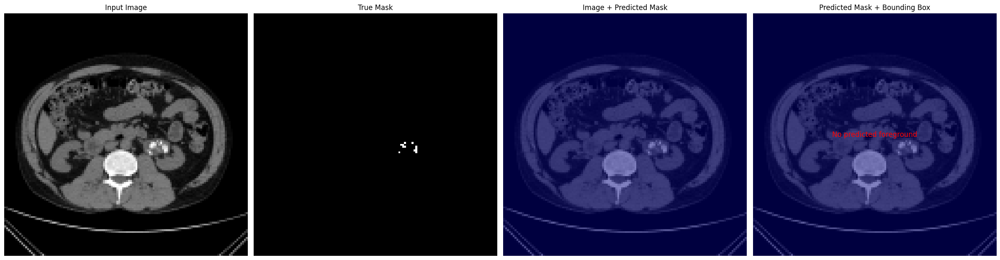

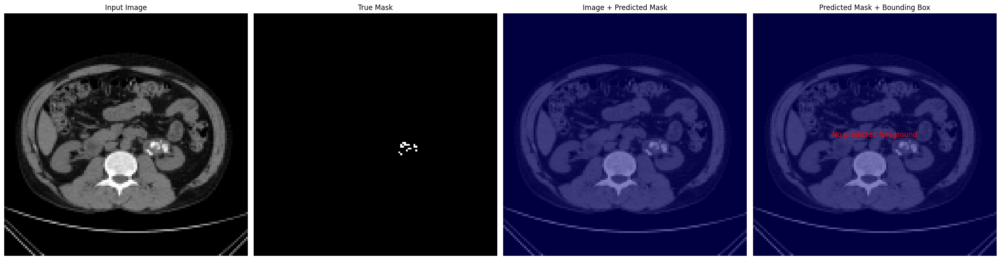

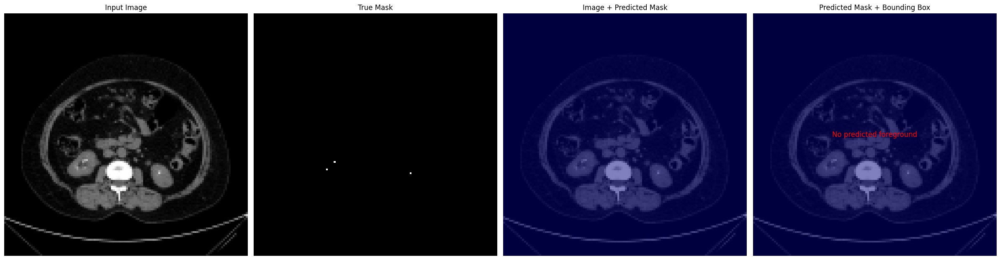

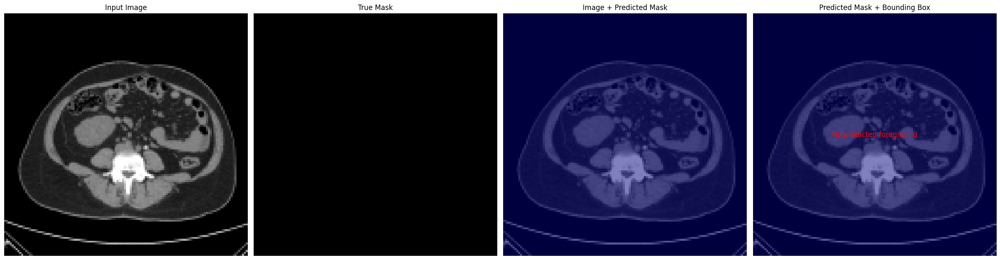

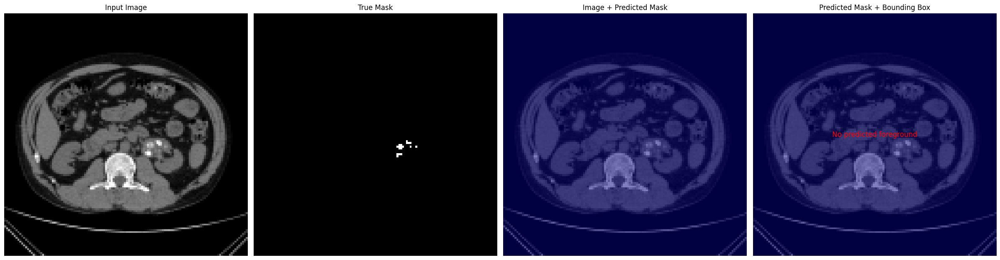

In [ ]:
show_predictions2(Test_dataset, num=10)

In [ ]:
for image, mask in Test_dataset.take(1):

    pred = model.predict(image, verbose=0)

    print("Prediction shape:", pred.shape)
    print("Prediction min:", pred.min())
    print("Prediction max:", pred.max())
    print("Prediction mean:", pred.mean())

    print("True mask shape:", mask.shape)
    print("True mask unique values:", np.unique(mask.numpy()))

Prediction shape: (8, 128, 128, 1)
Prediction min: 0.0
Prediction max: 0.0
Prediction mean: 0.0
True mask shape: (8, 128, 128)
True mask unique values: [0. 1.]


In [ ]:
pred_mask > 0.5

NameError: name 'pred_mask' is not defined

In [ ]:
print("True mask:", np.unique(mask.numpy()))
print("Prediction:", pred.min(), pred.max(), pred.mean())

True mask: [  0   1   2   3   4   5 252 253 254 255]
Prediction: 0.0 0.0 0.0
